# 06 · Experiment 5 — qualitative error analysis (and the UNCERTAIN verdict)

**Research question (Exp. 5):** where does the final system fail, and why? The brief asks for a qualitative analysis of **at least 15 difficult cases**.

**System analysed.** The best system from Exp. 2 and 4: **voice + face, late mean** (average of a voice-only and a face-only logistic regression). The transcript is left out because Exp. 4 showed it adds nothing.

**How we get a prediction for every clip.** 5-fold speaker-disjoint cross-validation: each clip is predicted by a model that never saw that clip's speaker. Inside each fold, 15% of the training speakers are held out to
tune the decision cut-off. So all 998 clips have an honest prediction (not just a 154-clip test set), which gives many more errors to study.

**UNCERTAIN.** As decided, UNCERTAIN means **low confidence**. Confidence is the distance of the fused score from the cut-off. The band is set on *validation* data so that about `ABSTAIN_TARGET` of clips fall inside it;
we then show accuracy versus coverage (the share of clips still answered).

**Outputs**
1. overall and per-category errors, plus a coverage-accuracy curve;
2. automatic failure tags (which modality was fooled, face crop fell back, empty transcript...);
3. `exp5_hard_cases.csv`: 20 hard cases chosen by rule, with scores, transcript and video path, and an empty `your_notes` column for you to watch the clips and write what you see.

**How to run on Kaggle:** add only `FakeAVCeleb-features`, accelerator None, Internet off, **Run All**. To *watch* the hard clips, also add the original FakeAVCeleb dataset as an input (the `path` column then resolves).

In [2]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

warnings.filterwarnings("ignore")
try:
    display
except NameError:
    display = lambda x: print(x.to_string() if hasattr(x, "to_string") else x)

SEED, K = 42, 5
CS = [1e-3, 1e-2, 1e-1, 1, 10]
ABSTAIN_TARGET = 0.15
N_CASES = 20
OUT = os.environ.get("EXP_OUT", "/kaggle/working/exp5")
os.makedirs(OUT, exist_ok=True)

def find(name):
    cands = []
    if os.environ.get("FEAT_DIR"):
        cands.append(os.path.join(os.environ["FEAT_DIR"], name))
    cands.append(os.path.join("/kaggle/working/features", name))
    cands += glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    for c in cands:
        if os.path.exists(c):
            return c
    raise FileNotFoundError(f"{name} not found. Add the FakeAVCeleb-features dataset as an input.")

Z = np.load(find("features.npz"))
meta = pd.read_csv(find("meta.csv")).sort_values("clip_id").reset_index(drop=True)
assert (Z["clip_id"] == meta.clip_id.values).all()
keep = ((meta.ok_img == 1) & (meta.ok_aud == 1)).values
meta = meta[keep].reset_index(drop=True)
V = Z["audio_layers"][keep].mean(1)
F = Z["image"][keep]
y, groups, cats = meta.label.values, meta.speaker.values, meta.category.values
print("clips:", len(meta), meta.category.value_counts().to_dict())

clips: 998 {'RVRA': 500, 'FVRA': 166, 'RVFA': 166, 'FVFA': 166}


## 1 · Out-of-fold predictions

In [3]:
def fit_lr(Xtr, ytr, Xva, yva):
    best = None
    for C in CS:
        clf = LogisticRegression(C=C, class_weight="balanced", max_iter=3000).fit(Xtr, ytr)
        a = roc_auc_score(yva, clf.predict_proba(Xva)[:, 1])
        if best is None or a > best[0]:
            best = (a, clf)
    return best[1]

def val_threshold(yv, pv):
    grid = np.linspace(0.05, 0.95, 91)
    sc = np.array([balanced_accuracy_score(yv, (pv >= t).astype(int)) for t in grid])
    cand = grid[sc >= sc.max() - 1e-12]
    return float(cand[np.argmin(np.abs(cand - 0.5))])

n = len(y)
pv_, pf_, pm_ = np.zeros(n), np.zeros(n), np.zeros(n)
thr_, band_, fold_ = np.zeros(n), np.zeros(n), np.zeros(n, int)
order = np.random.RandomState(SEED).permutation(len(np.unique(groups)))
gmap = dict(zip(np.unique(groups), order))
gk = np.array([gmap[g] for g in groups])            # shuffled group ids so the folds are not sorted by speaker
for k, (trv, te) in enumerate(GroupKFold(K).split(np.arange(n), groups=gk)):
    a, b = next(GroupShuffleSplit(1, test_size=0.15, random_state=SEED + k).split(trv, groups=groups[trv]))
    tr, va = trv[a], trv[b]
    P = {}
    for name, X in (("V", V), ("F", F)):
        sc = StandardScaler().fit(X[tr])
        clf = fit_lr(sc.transform(X[tr]), y[tr], sc.transform(X[va]), y[va])
        P[name] = (clf.predict_proba(sc.transform(X[va]))[:, 1], clf.predict_proba(sc.transform(X[te]))[:, 1])
    mv, mt = (P["V"][0] + P["F"][0]) / 2, (P["V"][1] + P["F"][1]) / 2
    thr = val_threshold(y[va], mv)
    band = np.quantile(np.abs(mv - thr), ABSTAIN_TARGET)      # half-width of the UNCERTAIN band, set on validation only
    pv_[te], pf_[te], pm_[te] = P["V"][1], P["F"][1], mt
    thr_[te], band_[te], fold_[te] = thr, band, k
    print(f"fold {k}: test clips {len(te)}  cut-off {thr:.2f}  UNCERTAIN half-width {band:.3f}")

pred = (pm_ >= thr_).astype(int)
verdict = np.where(np.abs(pm_ - thr_) <= band_, "UNCERTAIN", np.where(pred == 1, "FAKE", "REAL"))
dfp = meta[["clip_id", "category", "speaker", "label", "face_rate", "path", "transcript"]].copy()
dfp["p_voice"], dfp["p_face"], dfp["p_fused"], dfp["cutoff"] = pv_, pf_, pm_, thr_
dfp["pred"], dfp["verdict"], dfp["fold"] = pred, verdict, fold_
dfp["correct"] = (pred == y)
dfp["margin"] = (pm_ - thr_) * np.where(y == 1, 1, -1)       # >0 right side, <0 wrong side; bigger |.| = more confident
dfp.to_csv(f"{OUT}/exp5_all_predictions.csv", index=False)
print("pooled out-of-fold AUC:", round(roc_auc_score(y, pm_), 3), "| accuracy:", round(dfp.correct.mean(), 3))

fold 0: test clips 200  cut-off 0.53  UNCERTAIN half-width 0.066
fold 1: test clips 200  cut-off 0.44  UNCERTAIN half-width 0.043
fold 2: test clips 200  cut-off 0.47  UNCERTAIN half-width 0.065
fold 3: test clips 199  cut-off 0.53  UNCERTAIN half-width 0.045
fold 4: test clips 199  cut-off 0.44  UNCERTAIN half-width 0.067
pooled out-of-fold AUC: 0.936 | accuracy: 0.869


## 2 · Where are the errors?

In [4]:
CATS = ["RVRA", "RVFA", "FVRA", "FVFA"]
tab = dfp.groupby("category").agg(clips=("correct", "size"), accuracy=("correct", "mean"),
                                  uncertain=("verdict", lambda s: (s == "UNCERTAIN").mean())).reindex(CATS).round(3)
display(tab)
tab.to_csv(f"{OUT}/exp5_per_category.csv")

# face-crop quality and transcript length
dfp["face_found"] = pd.cut(dfp.face_rate, [-.01, .34, .67, 1.0], labels=["0-1 of 3 frames", "2 of 3 frames", "3 of 3 frames"])
dfp["words"] = dfp.transcript.fillna("").astype(str).str.split().str.len()
dfp["transcript_len"] = pd.cut(dfp.words, [-1, 0, 5, 12, 10_000], labels=["empty", "1-5 words", "6-12 words", ">12 words"])
for col in ("face_found", "transcript_len"):
    t = dfp.groupby(col).agg(clips=("correct", "size"), accuracy=("correct", "mean")).round(3)
    print("\naccuracy by", col); display(t)
    t.to_csv(f"{OUT}/exp5_by_{col}.csv")

# which modality was fooled
def tag(r):
    t = []
    v_f, f_f = r.p_voice >= 0.5, r.p_face >= 0.5
    if r.label == 1 and not r.correct:
        if r.category == "RVFA":
            t.append("voice-fake missed: voice model said real" if not v_f else "voice-fake: voice said fake but the face vote pulled the average under the cut-off")
        if r.category == "FVRA":
            t.append("face-fake missed: face model said real" if not f_f else "face-fake: face said fake but the voice vote pulled the average under the cut-off")
            if f_f and not v_f: t.append("confident voice vote overruled the face")
        if r.category == "FVFA":
            t.append("both-fake missed: both models said real" if not (v_f or f_f) else "both-fake missed: one model said fake, the other overruled it")
    if r.label == 0 and not r.correct:
        t.append("real flagged: voice model said fake" if v_f and not f_f else
                 "real flagged: face model said fake" if f_f and not v_f else "real flagged: both models said fake")
    if r.face_rate < 0.67: t.append("face crop unreliable (fallback frames)")
    if r.words <= 3: t.append("very short / empty transcript")
    return "; ".join(t)

dfp["tags"] = dfp.apply(tag, axis=1)
err = dfp[~dfp.correct]
from collections import Counter
cnt = Counter(t for s in err.tags for t in s.split("; ") if t)
display(pd.Series(cnt).sort_values(ascending=False).rename("errors").to_frame())

,clips,accuracy,uncertain
category,,,
RVRA,500,0.884,0.160
RVFA,166,0.916,0.187
FVRA,166,0.657,0.307
FVFA,166,0.988,0.030



accuracy by face_found


,clips,accuracy
face_found,,
0-1 of 3 frames,119,0.824
2 of 3 frames,132,0.894
3 of 3 frames,747,0.871



accuracy by transcript_len


,clips,accuracy
transcript_len,,
empty,0,NaN
1-5 words,5,1.000
6-12 words,152,0.875
>12 words,841,0.867


,errors
real flagged: face model said fake,44
face crop unreliable (fallback frames),35
confident voice vote overruled the face,30
face-fake: face said fake but the voice vote pulled the average under the cut-off,30
face-fake missed: face model said real,27
voice-fake: voice said fake but the face vote pulled the average under the cut-off,14
real flagged: both models said fake,9
real flagged: voice model said fake,5
"both-fake missed: one model said fake, the other overruled it",2


## 3 · UNCERTAIN: accuracy versus coverage
The more clips we are willing to leave unanswered, the more accurate the remaining answers should be. If accuracy does not rise, "low confidence" is not a useful signal.

In [5]:
conf = np.abs(pm_ - thr_)
rows = []
for cov in (1.0, 0.95, 0.9, 0.85, 0.8, 0.7, 0.6, 0.5):
    cut = np.quantile(conf, 1 - cov) if cov < 1 else -1
    m = conf >= cut
    rows.append(dict(coverage=cov, answered=int(m.sum()), accuracy=dfp.correct[m].mean(),
                     fake_recall=(pred[m & (y == 1)] == 1).mean(), real_acc=(pred[m & (y == 0)] == 0).mean()))
cov_df = pd.DataFrame(rows).round(3)
display(cov_df)
cov_df.to_csv(f"{OUT}/exp5_coverage_accuracy.csv", index=False)
u = dfp.verdict == "UNCERTAIN"
print(f"\nWith the validation-tuned band: {u.mean():.1%} of clips are UNCERTAIN; accuracy on the answered clips {dfp.correct[~u].mean():.3f} (vs {dfp.correct.mean():.3f} on all);"
      f" {(~dfp.correct[u]).mean():.1%} of the UNCERTAIN clips would have been wrong.")
print("share of all errors that fall inside the UNCERTAIN band:", round(float(((~dfp.correct) & u).sum() / max((~dfp.correct).sum(), 1)), 3))

,coverage,answered,accuracy,fake_recall,real_acc
0,1.00,998,0.869,0.853,0.884
1,0.95,948,0.881,0.868,0.894
2,0.90,898,0.895,0.883,0.907
3,0.85,848,0.904,0.896,0.913
4,0.80,798,0.919,0.909,0.928
5,0.70,698,0.936,0.921,0.949
6,0.60,599,0.950,0.932,0.967
7,0.50,499,0.966,0.956,0.976



With the validation-tuned band: 16.7% of clips are UNCERTAIN; accuracy on the answered clips 0.910 (vs 0.869 on all); 33.5% of the UNCERTAIN clips would have been wrong.
share of all errors that fall inside the UNCERTAIN band: 0.427


## 4 · The 20 hard cases
Chosen by rule, not by hand, so the selection is reproducible:
* **8 confident misses**: fakes the system called REAL with the largest margin (at least 2 per fake type if they exist);
* **5 confident false alarms**: real clips called FAKE with the largest margin;
* **4 borderline-wrong**: errors closest to the cut-off (these are the ones UNCERTAIN should catch);
* **3 borderline-right**: correct answers closest to the cut-off.

In [6]:
def take(df, k, by, asc):
    return df.sort_values(by, ascending=asc).head(k)

wrong = dfp[~dfp.correct].copy(); right = dfp[dfp.correct].copy()
miss = wrong[wrong.label == 1]
picked = []
for c in ("RVFA", "FVRA", "FVFA"):
    picked.append(take(miss[miss.category == c], 2, "margin", True))
picked = pd.concat(picked)
rest = miss.drop(picked.index)
picked = pd.concat([picked, take(rest, 8 - len(picked), "margin", True)]); picked["why_chosen"] = "confident miss"
fa = take(wrong[wrong.label == 0], 5, "margin", True).assign(why_chosen="confident false alarm")
used = set(picked.index) | set(fa.index)
bw = take(wrong.drop(list(used), errors="ignore"), 4, "margin", False).assign(why_chosen="borderline wrong")
br = take(right.assign(absm=right.margin.abs()), 3, "absm", True).drop(columns="absm").assign(why_chosen="borderline right")
hard = pd.concat([picked, fa, bw, br])
hard["your_notes"] = ""
cols = ["why_chosen", "clip_id", "category", "speaker", "verdict", "p_voice", "p_face", "p_fused", "cutoff", "face_rate", "tags", "transcript", "path", "your_notes"]
hard = hard[cols].round(3).reset_index(drop=True)
hard.to_csv(f"{OUT}/exp5_hard_cases.csv", index=False)
print(len(hard), "hard cases saved")
display(hard.drop(columns=["path", "transcript", "your_notes"]))

20 hard cases saved


,why_chosen,clip_id,category,speaker,verdict,p_voice,p_face,p_fused,cutoff,face_rate,tags
0,confident miss,359,RVFA,id01212,REAL,0.814,0.013,0.414,0.53,0.333,voice-fake: voice said fake but the face vote ...
1,confident miss,547,RVFA,id05479,REAL,0.742,0.138,0.440,0.53,1.000,voice-fake: voice said fake but the face vote ...
2,confident miss,35,FVRA,id01392,REAL,0.303,0.032,0.167,0.53,0.667,face-fake missed: face model said real; face c...
3,confident miss,898,FVRA,id01192,REAL,0.267,0.138,0.203,0.53,1.000,face-fake missed: face model said real
4,confident miss,23,FVFA,id01042,UNCERTAIN,0.824,0.072,0.448,0.47,1.000,"both-fake missed: one model said fake, the oth..."
5,confident miss,24,FVFA,id00519,UNCERTAIN,0.822,0.219,0.520,0.53,1.000,"both-fake missed: one model said fake, the oth..."
6,confident miss,229,FVRA,id09171,REAL,0.257,0.194,0.226,0.53,1.000,face-fake missed: face model said real
7,confident miss,611,FVRA,id05920,REAL,0.211,0.170,0.191,0.47,1.000,face-fake missed: face model said real
8,confident false alarm,922,RVRA,id03569,FAKE,0.553,0.924,0.738,0.44,0.333,real flagged: both models said fake; face crop...
9,confident false alarm,893,RVRA,id00033,FAKE,0.507,0.956,0.732,0.44,1.000,real flagged: both models said fake


## 5 · Figure

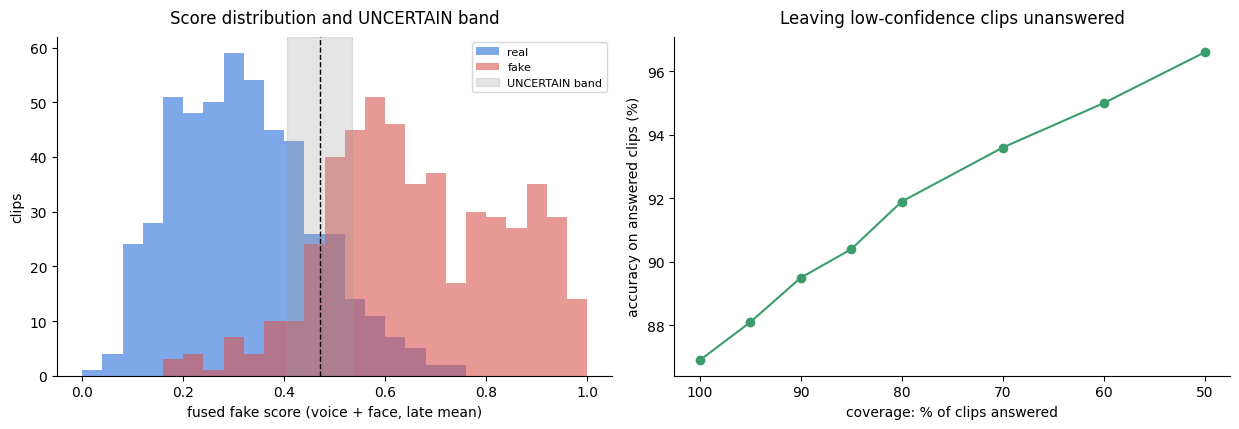

['exp5_all_predictions.csv', 'exp5_by_face_found.csv', 'exp5_by_transcript_len.csv', 'exp5_coverage_accuracy.csv', 'exp5_hard_cases.csv', 'exp5_per_category.csv', 'exp5_uncertain_and_scores.png']


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4))
bins = np.linspace(0, 1, 26)
for lab, m, col in (("real", y == 0, "#2a6fdb"), ("fake", y == 1, "#d9534f")):
    ax[0].hist(pm_[m], bins=bins, alpha=.6, label=lab, color=col)
ax[0].axvline(np.median(thr_), c="k", ls="--", lw=1)
ax[0].axvspan(np.median(thr_ - band_), np.median(thr_ + band_), color="#999", alpha=.25, label="UNCERTAIN band")
ax[0].set_xlabel("fused fake score (voice + face, late mean)"); ax[0].set_ylabel("clips"); ax[0].legend(fontsize=8)
ax[0].set_title("Score distribution and UNCERTAIN band", pad=10)
ax[1].plot(cov_df.coverage * 100, cov_df.accuracy * 100, "o-", c="#3a9d6b")
ax[1].set_xlabel("coverage: % of clips answered"); ax[1].set_ylabel("accuracy on answered clips (%)")
ax[1].invert_xaxis(); ax[1].set_title("Leaving low-confidence clips unanswered", pad=10)
for x in ax: x.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(f"{OUT}/exp5_uncertain_and_scores.png", dpi=150); plt.show()
print(sorted(os.listdir(OUT)))